# Reto 4 · Interpretación de los segmentos

Traducimos los 5 clusters a **perfiles de cliente** que un equipo de marketing pueda usar: quién es, qué tiene,
cómo se relaciona con la marca y qué acción le corresponde.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import plot_style as ps
import mb_features as mf

ps.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CSV = next(p for p in [DATA_DIR / "datos_reto_mercedes_benz_malackathon.csv",
                       ROOT / "datos_reto_mercedes_benz_malackathon.csv"] if p.exists())

In [2]:
clients = pd.read_pickle(DATA_DIR / "clients.pkl")
labels = pd.read_pickle(DATA_DIR / "labels_kmeans.pkl")
df = clients.join(labels)
K = df.cluster.nunique()
print(df.shape, K)

(173456, 44) 5


## 1. Nombrado de los segmentos

Los nombres se asignan con reglas sobre los centroides (no a mano), para que sean reproducibles aunque cambie la numeración de K-Means:

In [3]:
prof = df.groupby("cluster").agg(
    currently_connected_vehicles=("currently_connected_vehicles", "mean"),
    main_electrification=("main_electrification", "mean"),
    workshop_visits_per_vehicle=("workshop_visits_per_vehicle", "mean"),
    main_vehicle_age_years=("main_vehicle_age_years", "mean"),
    tenure_years=("tenure_years", "mean"),
)
names, remaining = {}, set(prof.index)
def take(col, name, largest=True):
    c = prof.loc[list(remaining), col]
    k = c.idxmax() if largest else c.idxmin()
    names[k] = name; remaining.discard(k)
take("currently_connected_vehicles", "Flotas y Multi-Estrella")
take("main_electrification", "Pioneros Eléctricos")
take("workshop_visits_per_vehicle", "Premium Fieles al Taller")
take("main_vehicle_age_years", "Veteranos a Renovar")
for k in remaining:
    names[k] = "Recién Llegados Compactos"
ORDER = ["Recién Llegados Compactos", "Veteranos a Renovar", "Premium Fieles al Taller",
         "Pioneros Eléctricos", "Flotas y Multi-Estrella"]
df["segmento"] = pd.Categorical(df.cluster.map(names), categories=ORDER, ordered=True)
COLORS = dict(zip(ORDER, ps.SERIES))
df.segmento.value_counts().reindex(ORDER).to_frame("clientes").assign(
    pct=lambda d: (d.clientes / d.clientes.sum() * 100).round(1), cluster=lambda d: [
        [k for k, v in names.items() if v == s][0] for s in d.index])

,clientes,pct,cluster
segmento,,,
Recién Llegados Compactos,38910,22.4,3
Veteranos a Renovar,36367,21.0,0
Premium Fieles al Taller,55650,32.1,2
Pioneros Eléctricos,32948,19.0,4
Flotas y Multi-Estrella,9581,5.5,1


## 2. Tabla de perfilado por segmento

In [4]:
def pct(cond): return lambda s: cond(s).mean() * 100
g = df.groupby("segmento", observed=True)
profile = pd.concat({
    "Clientes": g.size(),
    "% del total": g.size() / len(df) * 100,
    "Edad 55+ (%)": g.age_range.apply(lambda s: s.isin(["55-64", "65+"]).mean() * 100),
    "Edad <35 (%)": g.age_range.apply(lambda s: s.isin(["<25", "25-34"]).mean() * 100),
    "Mujeres (%) (inferido)": g.gender_derived.apply(lambda s: (s == "female").mean() * 100),
    "Suiza (%)": g.country_code.apply(lambda s: (s == "CH").mean() * 100),
    "Poder adquisitivo hogar (k€, mediana)": g.purchasing_power_per_household_eur.median() / 1000,
    "Años como cliente (media)": g.tenure_years.mean(),
    "Vehículos conectados (media)": g.currently_connected_vehicles.mean(),
    "Vehículos en historial (media)": g.n_vehicles_history.mean(),
    "Sin vehículo actual (%)": g.currently_connected_vehicles.apply(lambda s: (s == 0).mean() * 100),
    "Antigüedad vehículo (años, mediana)": g.main_vehicle_age_years.median(),
    "Gama media (1-4)": g.main_segment_tier.mean(),
    "Gama superior/lujo (%)": g.main_segment_tier.apply(lambda s: (s >= 3).mean() * 100),
    "SUV (%)": g.main_is_suv.mean() * 100,
    "Furgoneta (%)": g.main_is_van.mean() * 100,
    "AMG (%)": g.main_is_amg.mean() * 100,
    "Electrificado PHEV/EV (%)": g.main_electrification.apply(lambda s: (s >= 2).mean() * 100),
    "Eléctrico puro (%)": g.main_electrification.apply(lambda s: (s == 3).mean() * 100),
    "Financiación activa (%)": g.finance_active.mean() * 100,
    "Financiación alguna vez (%)": g.finance_ever.mean() * 100,
    "B2B (%)": g.is_b2b.mean() * 100,
    "Visitas taller / vehículo": g.workshop_visits_per_vehicle.mean(),
    "Acepta teléfono (%)": g.consent_phone_communication_channel.mean() * 100,
    "Acepta correo postal (%)": g.consent_post_communication_channel.mean() * 100,
    "Con telemetría (%)": g.has_telemetry.mean() * 100,
    "Km medios por trayecto": g.trip_distance_average.median(),
    "Horas de uso totales (mediana)": g.operating_hours_total.median(),
}, axis=1).T
profile.round(1)

segmento,Recién Llegados Compactos,Veteranos a Renovar,Premium Fieles al Taller,Pioneros Eléctricos,Flotas y Multi-Estrella
Clientes,38910.0,36367.0,55650.0,32948.0,9581.0
% del total,22.4,21.0,32.1,19.0,5.5
Edad 55+ (%),36.5,34.0,39.4,51.5,37.5
Edad <35 (%),25.6,30.1,17.2,9.8,15.2
Mujeres (%) (inferido),17.6,13.8,22.7,17.5,11.2
Suiza (%),58.3,52.2,89.2,53.9,59.6
"Poder adquisitivo hogar (k€, mediana)",94.4,85.1,115.6,93.0,99.2
Años como cliente (media),1.4,2.5,3.9,2.5,4.7
Vehículos conectados (media),0.9,0.8,1.0,1.0,2.8
Vehículos en historial (media),1.2,1.1,1.3,1.4,9.9


## 3. Mapa de calor: ¿qué hace distinto a cada segmento?

Diferencia de cada segmento respecto a la media global, en desviaciones típicas (z-score de la media del segmento).
Naranja = por encima de la media, azul = por debajo.

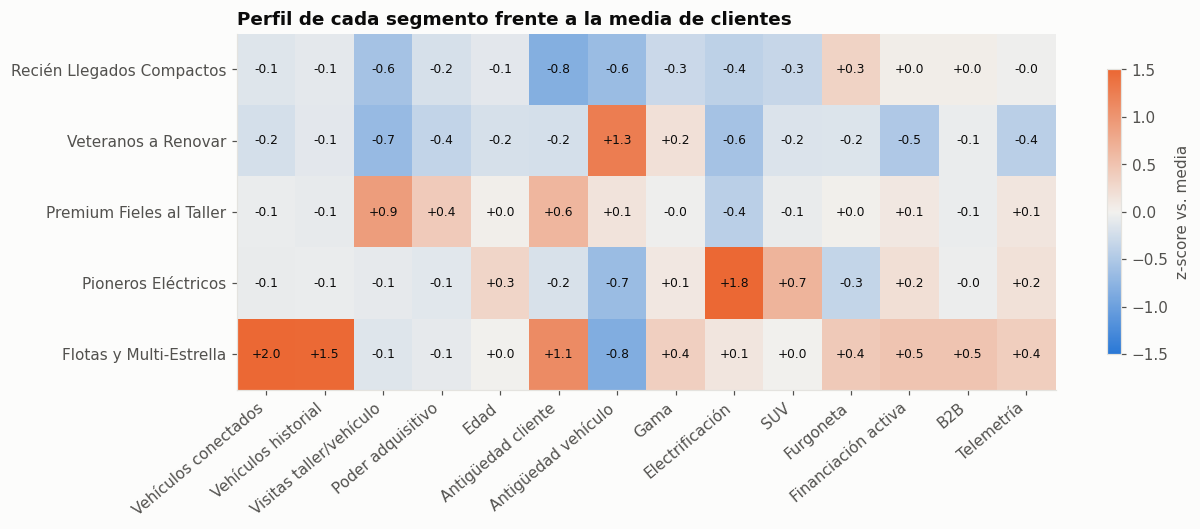

In [5]:
vars_ = {"currently_connected_vehicles": "Vehículos conectados", "n_vehicles_history": "Vehículos historial",
         "workshop_visits_per_vehicle": "Visitas taller/vehículo", "purchasing_power_per_household_eur": "Poder adquisitivo",
         "age_ord": "Edad", "tenure_years": "Antigüedad cliente", "main_vehicle_age_years": "Antigüedad vehículo",
         "main_segment_tier": "Gama", "main_electrification": "Electrificación", "main_is_suv": "SUV",
         "main_is_van": "Furgoneta", "finance_active": "Financiación activa", "is_b2b": "B2B",
         "has_telemetry": "Telemetría"}
num = df[list(vars_)].astype(float)
z = ((num.groupby(df.segmento, observed=True).mean() - num.mean()) / num.std()).rename(columns=vars_)
fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(z.values, cmap=ps.DIVERGING, vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(z.shape[1]), z.columns, rotation=40, ha="right")
ax.set_yticks(range(z.shape[0]), z.index); ax.grid(False)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f"{z.values[i, j]:+.1f}", ha="center", va="center", fontsize=8, color=ps.INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="z-score vs. media")
ax.set_title("Perfil de cada segmento frente a la media de clientes")
fig.savefig(FIG_DIR / "04_heatmap_segmentos.png"); plt.show()

## 4. Gráficos de perfilado

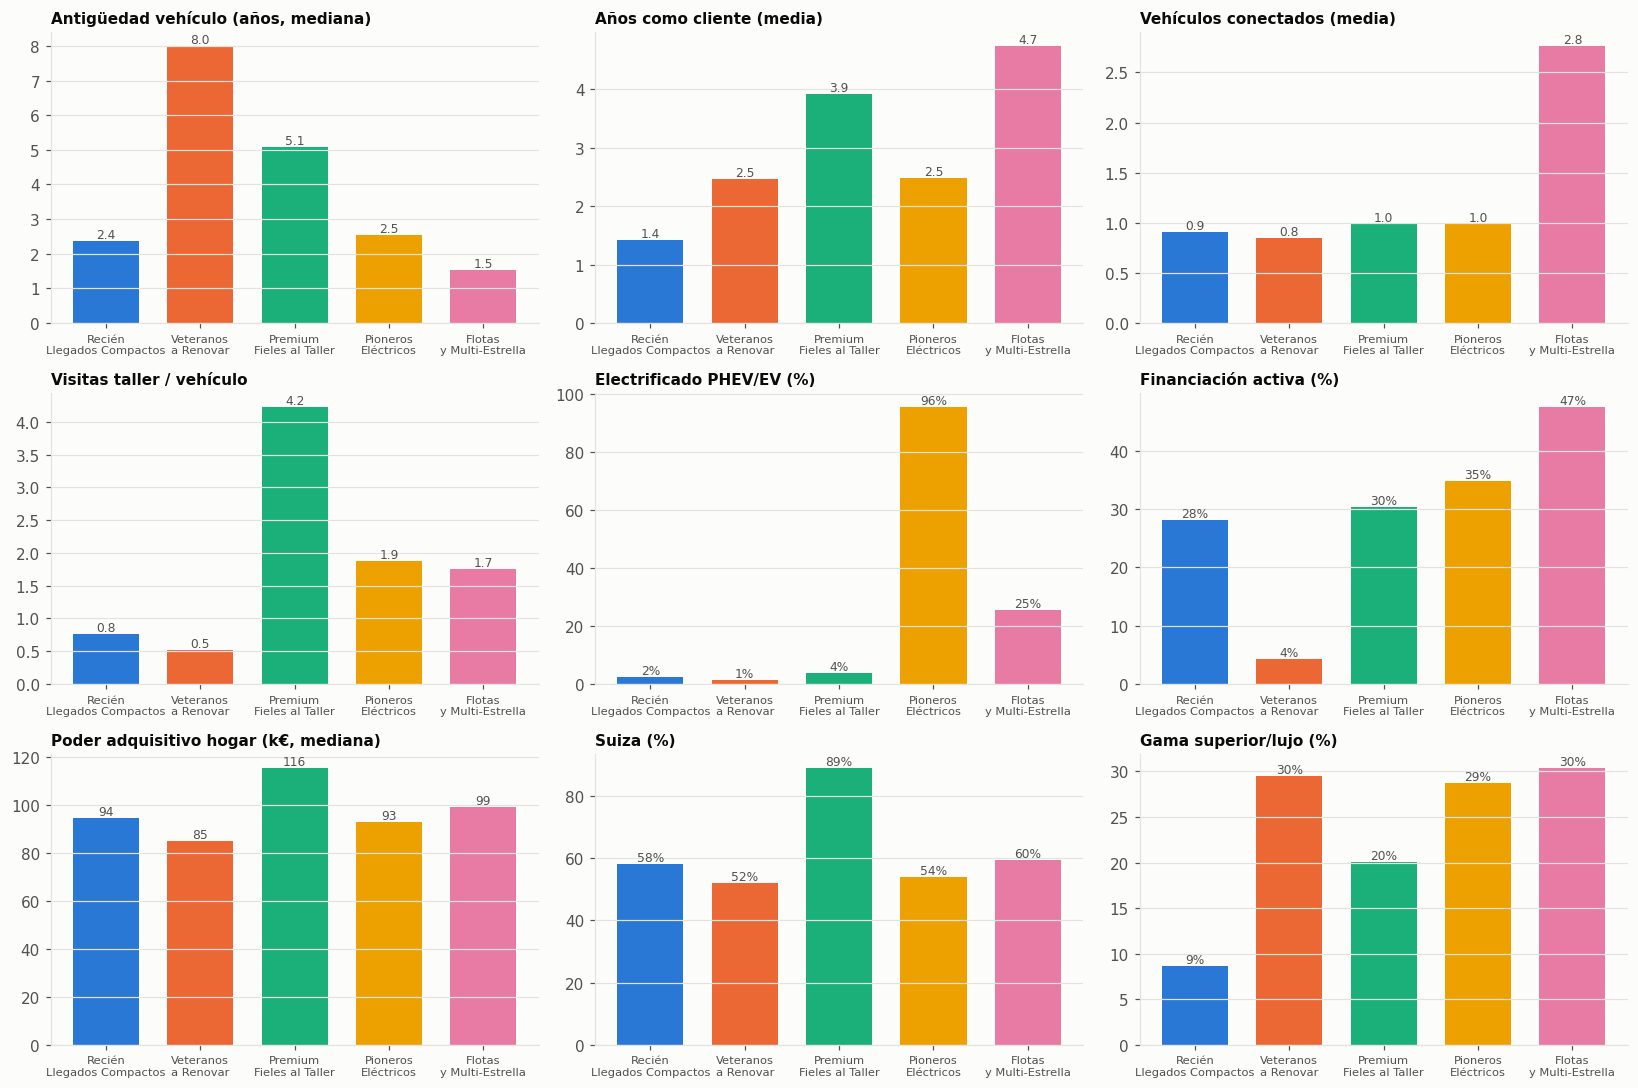

In [6]:
kpis = [("Antigüedad vehículo (años, mediana)", "{:.1f}"), ("Años como cliente (media)", "{:.1f}"),
        ("Vehículos conectados (media)", "{:.1f}"), ("Visitas taller / vehículo", "{:.1f}"),
        ("Electrificado PHEV/EV (%)", "{:.0f}%"), ("Financiación activa (%)", "{:.0f}%"),
        ("Poder adquisitivo hogar (k€, mediana)", "{:.0f}"), ("Suiza (%)", "{:.0f}%"),
        ("Gama superior/lujo (%)", "{:.0f}%")]
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, (k, fmt) in zip(axes.ravel(), kpis):
    vals = profile.loc[k, ORDER]
    ps.bar(ax, range(len(ORDER)), vals.values, color=[COLORS[s] for s in ORDER], fmt=fmt)
    ax.set_xticks(range(len(ORDER)), [s.replace(" ", "\n", 1) for s in ORDER], fontsize=7.5)
    ax.set_title(k, fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / "04_kpis_segmentos.png"); plt.show()

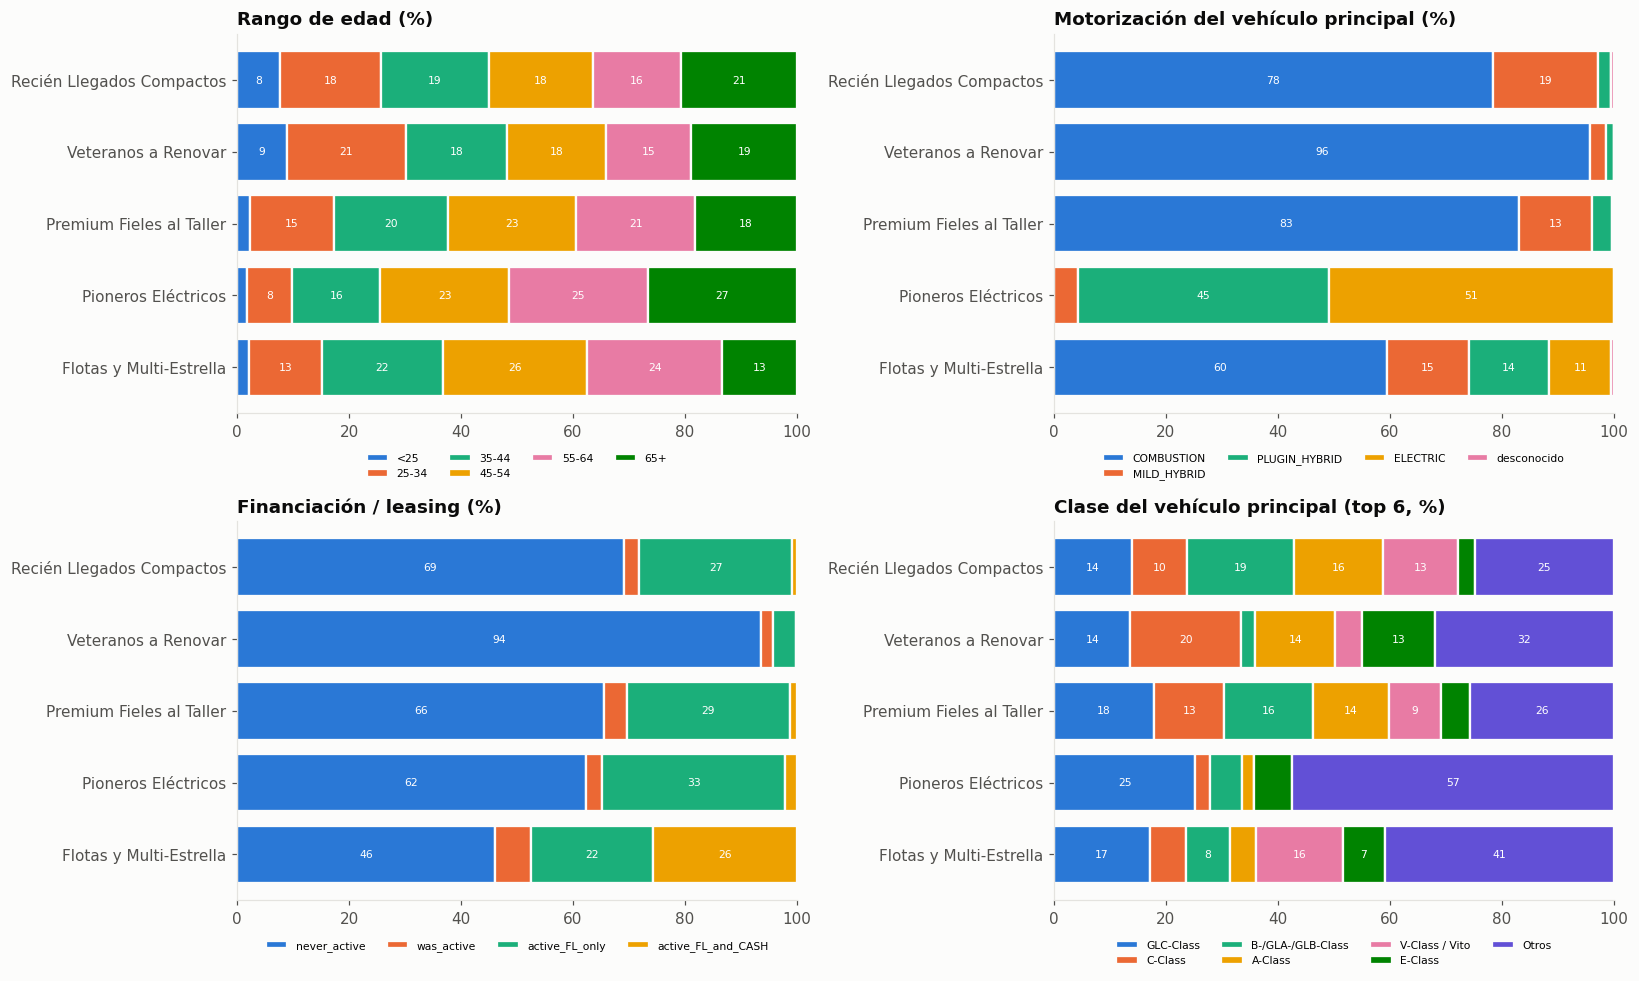

In [7]:
def stacked(ax, col, title, order=None, top=None):
    ct = pd.crosstab(df.segmento, df[col].fillna("desconocido"), normalize="index") * 100
    if top: ct = ct[ct.sum().sort_values(ascending=False).index[:top]]; ct["Otros"] = 100 - ct.sum(axis=1)
    if order: ct = ct[[c for c in order if c in ct.columns] + [c for c in ct.columns if c not in order]]
    left = np.zeros(len(ct))
    pal = ps.SERIES + ["#b5b4ad", "#8d8c85"]
    for j, c in enumerate(ct.columns):
        ax.barh(ct.index.astype(str), ct[c], left=left, color=pal[j % len(pal)], edgecolor="#fcfcfb", lw=1.5, label=str(c))
        for i, v in enumerate(ct[c]):
            if v > 7: ax.text(left[i] + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white")
        left += ct[c].values
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_title(title); ax.grid(False)
    ax.legend(ncol=min(len(ct.columns), 4), fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.08))

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
stacked(axes[0, 0], "age_range", "Rango de edad (%)", order=list(mf.AGE_ORDER))
stacked(axes[0, 1], "main_engine_concept", "Motorización del vehículo principal (%)",
        order=["COMBUSTION", "MILD_HYBRID", "PLUGIN_HYBRID", "ELECTRIC"])
stacked(axes[1, 0], "finance_leasing_status", "Financiación / leasing (%)",
        order=["never_active", "was_active", "active_FL_only", "active_FL_and_CASH"])
stacked(axes[1, 1], "main_model_class", "Clase del vehículo principal (top 6, %)", top=6)
fig.tight_layout(); fig.savefig(FIG_DIR / "04_composicion_segmentos.png"); plt.show()

In [8]:
# Top modelos concretos por segmento
top_models = (df.groupby("segmento", observed=True).main_vehicle_type
                .apply(lambda s: ", ".join(f"{m} ({p:.0%})" for m, p in s.value_counts(normalize=True).head(4).items())))
top_models.to_frame("modelos más frecuentes")

,modelos más frecuentes
segmento,
Recién Llegados Compactos,"GLC 220 d 4MATIC (6%), C 220 d 4MATIC (3%), A ..."
Veteranos a Renovar,"GLC 220 d 4MATIC (4%), E 220 d (3%), E 220 d 4..."
Premium Fieles al Taller,"GLC 220 d 4MATIC (5%), C 220 d 4MATIC (3%), GL..."
Pioneros Eléctricos,"GLC 300 de 4MATIC (9%), GLC 300 e 4MATIC (7%),..."
Flotas y Multi-Estrella,"GLC 220 d 4MATIC (3%), GLC 300 de 4MATIC (3%),..."


## 5. Perfil de negocio de cada segmento

> Las cifras citadas corresponden a la tabla de perfilado de la sección 2.

### 🟦 Recién Llegados Compactos (22 %)
**Quiénes son:** los clientes **más nuevos** (≈1,4 años con la marca) con un **coche reciente** (mediana 2,4 años) de **gama compacta**
(la gama más baja: solo un 9 % en gama superior), con un 21 % de furgonetas de uso particular. Apenas usan aún el taller (0,8 visitas/vehículo).
**Oportunidad:** consolidar la relación en los primeros años y llevarlos hacia arriba en gama.
**Acciones:** onboarding digital (app Mercedes me, servicios conectados), **primer plan de mantenimiento prepago**,
upgrade a gama media (Clase C / GLC) en el próximo cambio. Canal: email / app.

### 🟧 Veteranos a Renovar (21 %)
**Quiénes son:** clientes con el **vehículo más antiguo** (mediana 8 años, muchas Clase E y GLC de generación anterior), comprado
**sin financiación** de la marca (solo un 6 % la ha usado), con el **menor uso del taller oficial** (0,5 visitas/vehículo), poca telemetría
y el **menor poder adquisitivo** de zona. Son, curiosamente, el segmento **más joven** (30 % menores de 35): perfil compatible con compradores
de segunda mano. El 17 % ya no tiene vehículo conectado: hay riesgo real de fuga.
**Oportunidad:** están en plena **ventana de renovación**.
**Acciones:** **ofertas de vehículo** con valoración del usado / plan renove, **seminuevos certificados con financiación** (puerta de entrada
a Mercedes-Benz Financial), campaña de **recuperación de posventa** (revisión a precio cerrado para coches > 5 años). Canal: teléfono y correo postal.

### 🟩 Premium Fieles al Taller (32 %)
**Quiénes son:** el segmento más grande, casi todo **suizo** (89 %) y con el **mayor poder adquisitivo** (≈116 k€ por hogar);
clientes veteranos (≈4 años) que usan **intensivamente el taller oficial** (≈4,2 visitas en garantía por vehículo, más del doble que el resto)
y con la mayor proporción de **AMG** (19 %).
**Oportunidad:** alta rentabilidad de posventa y confianza en la red oficial.
**Acciones:** **planes de mantenimiento premium** / extensión de garantía, programa de fidelización con servicios exclusivos
(recogida y entrega, vehículo de sustitución), upsell a gama superior (Clase E, GLE) y AMG. Canal: concesionario + teléfono.

### 🟨 Pioneros Eléctricos (19 %)
**Quiénes son:** el 96 % conduce un **PHEV o eléctrico puro** (51 % 100 % eléctrico: EQA/EQB, EQE…; el resto GLC 300 e/de), el 65 % en **SUV**.
Es el segmento **de más edad** (51 % con 55+ años) y con coche reciente (2,5 años); un 35 % con financiación activa.
**Oportunidad:** son la base de la transición eléctrica de la marca y los usuarios con más servicios digitales.
**Acciones:** comunicaciones sobre **carga** (wallbox, tarifas, Mercedes me Charge), actualizaciones OTA y suscripciones digitales,
renovación del leasing hacia la nueva generación EQ; tono sobrio orientado a confort y seguridad. Canal: email / app.

### 🟥 Flotas y Multi-Estrella (5,5 %)
**Quiénes son:** el segmento más pequeño pero de mayor valor por cliente: **≈2,8 vehículos conectados** a la vez y ≈10 en su historial,
los coches **más nuevos** (1,5 años), la mayor proporción de **B2B** (4 %, 7 veces la media) y de **furgonetas** (24 %: Vito, Sprinter),
los clientes más antiguos (≈4,7 años) y casi la mitad con **financiación activa** (48 %).
**Oportunidad:** concentran un volumen de vehículos muy superior a su número de clientes.
**Acciones:** **gestor de cuentas** dedicado, contratos de **leasing de flota y mantenimiento por volumen**, ofertas para
electrificar la flota (eVito, eSprinter), condiciones para el resto de conductores del hogar o la empresa. Canal: comercial directo.

In [9]:
# Ficha resumen exportable para marketing
fichas = pd.DataFrame({
    "Segmento": ORDER,
    "Peso (%)": profile.loc["% del total", ORDER].round(1).values,
    "Rasgo clave": ["Cliente nuevo, coche compacto reciente",
                    "Coche de ~8 años, sin financiación, fuera del taller oficial",
                    "Alto poder adquisitivo, Suiza, mucho taller oficial",
                    "PHEV/EV, SUV, 55+ años",
                    "Varios coches, B2B y furgonetas"],
    "Ofertas de vehículos": ["Upgrade a gama media", "Plan renove + test-drive híbrido/EV", "Upsell gama superior / AMG",
                             "Renovación hacia nueva gama EQ", "Leasing de flota / eVans"],
    "Planes de mantenimiento": ["Primer plan prepago", "Revisión a precio cerrado >5 años", "Plan premium + extensión garantía",
                                "Servicio EV + batería", "Mantenimiento por volumen"],
    "Fidelización": ["Onboarding Mercedes me", "Recuperación / win-back", "Programa VIP de servicios",
                     "Ecosistema de carga", "Gestor de cuenta"],
    "Canal preferente": ["Email / app", "Teléfono / correo postal", "Concesionario / teléfono", "Email / app", "Comercial directo"],
})
fichas.to_csv(ROOT / "reports" / "fichas_segmentos.csv", index=False)
df[["cluster", "segmento"]].reset_index().to_csv(DATA_DIR / "clientes_segmentados.csv", index=False)
fichas

,Segmento,Peso (%),Rasgo clave,Ofertas de vehículos,Planes de mantenimiento,Fidelización,Canal preferente
0,Recién Llegados Compactos,22.4,"Cliente nuevo, coche compacto reciente",Upgrade a gama media,Primer plan prepago,Onboarding Mercedes me,Email / app
1,Veteranos a Renovar,21.0,"Coche de ~8 años, sin financiación, fuera del ...",Plan renove + test-drive híbrido/EV,Revisión a precio cerrado >5 años,Recuperación / win-back,Teléfono / correo postal
2,Premium Fieles al Taller,32.1,"Alto poder adquisitivo, Suiza, mucho taller of...",Upsell gama superior / AMG,Plan premium + extensión garantía,Programa VIP de servicios,Concesionario / teléfono
3,Pioneros Eléctricos,19.0,"PHEV/EV, SUV, 55+ años",Renovación hacia nueva gama EQ,Servicio EV + batería,Ecosistema de carga,Email / app
4,Flotas y Multi-Estrella,5.5,"Varios coches, B2B y furgonetas",Leasing de flota / eVans,Mantenimiento por volumen,Gestor de cuenta,Comercial directo
